# Validity and tightness

Verification notebook. It reruns the Chapter 6 checks against `lrd.core` and `lrd.worst_case`. Checks: the bound is never violated (V5.1); the tightness criterion in the generic regime (V5.3), the tied regime with the full face (V5.2), and against certified KKT truth (V5.4); distances to degeneracy (V5.5); and the one-hot case with the tightness-accuracy identity (V5.6, Figure 3); and the self-certifying solution (V3.7, slow: about a minute).

In [1]:
from lrd.checks import validity
from lrd import paths
import numpy as np
import matplotlib.pyplot as plt

## V5.1 — the bound is never below the truth

The closed form $\langle\hat p,f\rangle + \varepsilon D_r(f)$ upper-bounds the true worst case, checked against the exact LP at $r^*\in\{1,\infty\}$ and certified KKT at $r^*=2$, over all three members.

In [2]:
validity.v5_1()

PASS  V5.1: the bound is never below the truth  [lem:upperbound]
  => 1500 instances across r* in 1,2,inf: closed form below truth = 0, solver failures = 0, max gap = 5.168 nats

## V5.3 — the tightness criterion, generic regime

The bound is tight if and only if the face $\{\hat p + \varepsilon g : g\in\partial D_r(f)\}$ meets the nonnegative orthant. On generic data the subgradient is a single point, so the canonical single-vertex check is exact. We cross-tabulate tightness (LP) against feasibility of that vertex; off-diagonal cells would refute the criterion.

In [3]:
validity.v5_3()

PASS  V5.3: tightness criterion, generic regime  [prop:tightness]
    tt = tight & feasible, ff = loose & infeasible, tf/ft = off-diagonal (must be 0)
    r*=1:  {'tt': 360, 'tf': 0, 'ft': 0, 'ff': 240}
    r*=inf:  {'tt': 158, 'tf': 0, 'ft': 0, 'ff': 442}
  => off-diagonal (criterion disagrees with LP) = 0

## V5.2 — the tied regime: the criterion is existential

With integer-valued $f$ (forcing ties) and a zero in $\hat p$, the subgradient is set-valued, and the criterion asks whether *some* face element is feasible. The full face test agrees with the LP, while the canonical single-vertex check misses feasible cases. One hand-built instance shows the gap.

In [4]:
validity.v5_2()

PASS  V5.2: tightness, tied regime: the criterion is existential  [prop:tightness]
    face test vs LP: {'tt': 283, 'tf': 0, 'ft': 0, 'ff': 117}   (off-diagonal must be 0)
    canonical single-vertex check missed 102 face-feasible instances
    counterexample p=(0,.5,.3,.2), f=(0,0,1,1), eps=.4:
      canonical vertex feasible? False;  face feasible? True;  LP 0.700000 vs closed form 0.700000
  => face test exact (off-diagonal 0); canonical vertex misses 102/400

## V5.4 — the criterion at $r^*=2$, against certified KKT

The Euclidean member has no LP; we test the criterion against the certified KKT value from `inner_p2`. The criterion must agree with tightness on every certified instance.

In [5]:
validity.v5_4()

PASS  V5.4: tightness at r* = 2 vs certified KKT  [prop:tightness]
  => 400/400 certified instances, criterion-vs-truth disagreements 0

## V5.5 — distance to degeneracy

The criterion is exact away from ties. This shows ties are not lurking arbitrarily close: the first-percentile distance to degeneracy stays well above zero on realistic logit draws.

In [6]:
validity.v5_5()

PASS  V5.5: distance to degeneracy on synthetic logits  [prop:tightness]
    r=   1:  1st percentile distance 2.6e-03,  median 2.54e-01
    r= inf:  1st percentile distance 5.2e-03,  median 5.14e-01
  => 1st percentile distance >= 2.6e-03 (tie margin 1e-06)

## V5.6 — one-hot targets and the tightness-accuracy identity

For a one-hot $\hat p = e_k$ the $\ell_1$ certificate is tight exactly when $\arg\max x = k$ and $\varepsilon \le 2$: tight precisely on correctly classified examples. At fixed $\varepsilon = 1$, the tightness rate equals the accuracy across a logit-offset sweep, which is Figure 3.

PASS  V5.6: one-hot tightness equals correct classification  [prop:onehot]
  => 660 instances, criterion-vs-LP disagreements 0; max|tightness rate - accuracy| at eps=1 = 0.0


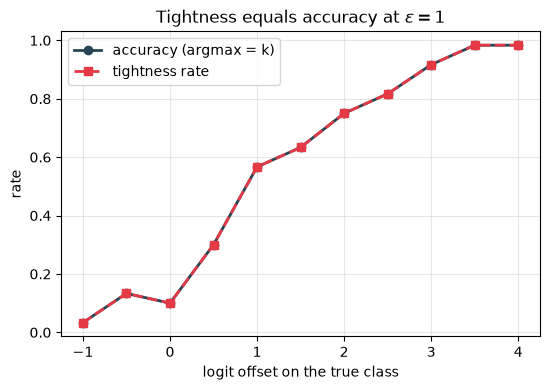

In [7]:
v5_6 = validity.v5_6()
print(v5_6)
d = v5_6.data
fig, ax = plt.subplots(figsize=(5.6, 4))
ax.plot(d['offsets'], d['accuracy'], 'o-', color='#264653', lw=2, label='accuracy (argmax = k)')
ax.plot(d['offsets'], d['tightness'], 's--', color='#e63946', lw=2, label='tightness rate')
ax.set_xlabel('logit offset on the true class'); ax.set_ylabel('rate')
ax.set_title(r'Tightness equals accuracy at $\varepsilon=1$')
ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(paths.figure('fig_tightness.pdf'), bbox_inches='tight')
plt.show()

## V3.7 — the solution is self-certifying

At the penalised solution $x^\star$, with $f^\star=-\log x^\star$, the bound is exact, $U(f^\star)=W(f^\star)=H(x^\star)$; $x^\star$ is the minimax predictor over the ball and its maximum-entropy point. Each part is tested against an independent instrument: $x^\star$ lies in the ball; the identity against the exact worst case; no perturbed challenger has a lower exact worst case; and an independent maximiser finds no point of the ball with higher entropy. Radii from $0.01$ to $0.999\,\varepsilon_{\mathrm{sat}}$, nominals with zero coordinates. Slow: about a minute.

In [8]:
validity.v3_7()  # slow: about a minute

PASS  V3.7: the solution is self-certifying  [prop:selfcert]
    180 instances across r* in 1,2,inf; eps in [0.01, 0.999] eps_sat
    max ||x* - ph|| - eps           = 4.9e-09  (want <= SOLVER_TOL)
    max |U - H|, |W - H|            = 4.13e-09 nats  (want <= SOLVER_TOL)
    max W(x*) - W(challenger)       = 0.0e+00  (want <= SOLVER_TOL)
    max H(maxent point) - H(x*)     = 4.1e-09  (want <= SOLVER_TOL)
    instances where SLSQP found no feasible point: 2
  => identity 4.1e-09 nats; no challenger beats x* (max gain 0.0e+00); no feasible point has higher entropy (max excess 4.1e-09)